In [ ]:
"""Run AGREED on Default-Credit and plot the local and global group importance"""

from IPython.display import display
import os
import time
import matplotlib.pyplot as plt
from matplotlib import rc

rc("font", **{"family": "serif", "serif": ["Computer Modern Roman"], "size": 20})
rc("text", usetex=True)
import numpy as np
from joblib import load
from pyfd.decompositions import get_components_ebm
from pyfd.decompositions import get_interventional_from_anchored, get_PDP_PFI_importance
from pyfd.shapley import shap_from_decomposition, get_SHAP_importance
from pyfd.plots import bar, partial_dependence_plot

# Local
from utils import custom_train_test_split

from agreed.dataset.tabular.factory import get_data_marketing
from agreed.explainers.tabular.grouping import TabularAGREED


In [ ]:
np.random.seed(42)
X, y, features = get_data_marketing()
task = "classification"

x_train, x_test, y_train, y_test = custom_train_test_split(X, y.ravel(), task)
background = x_test[np.random.choice(x_test.shape[0], 1000, replace=False)]
N, d = background.shape

# Save the model for later
model = load(os.path.join("models", "ebm_marketing.joblib"))
display(model)
display(model.score(x_test, y_test))


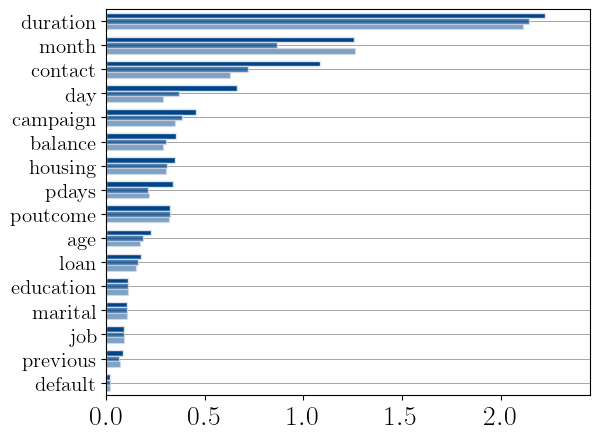

In [3]:
# Compute the functional decomposition using PyFD
decomposition = get_components_ebm(
    model, background, background, features, anchored=True
)
shap_values = shap_from_decomposition(get_interventional_from_anchored(decomposition))
I_PDP, I_PFI = get_PDP_PFI_importance(decomposition)
I_SHAP = get_SHAP_importance(shap_values)

bar([I_PFI, I_SHAP, I_PDP], feature_labels=features.names())
plt.savefig(os.path.join("results", "GFI_ebm_marketing.pdf"), bbox_inches="tight")


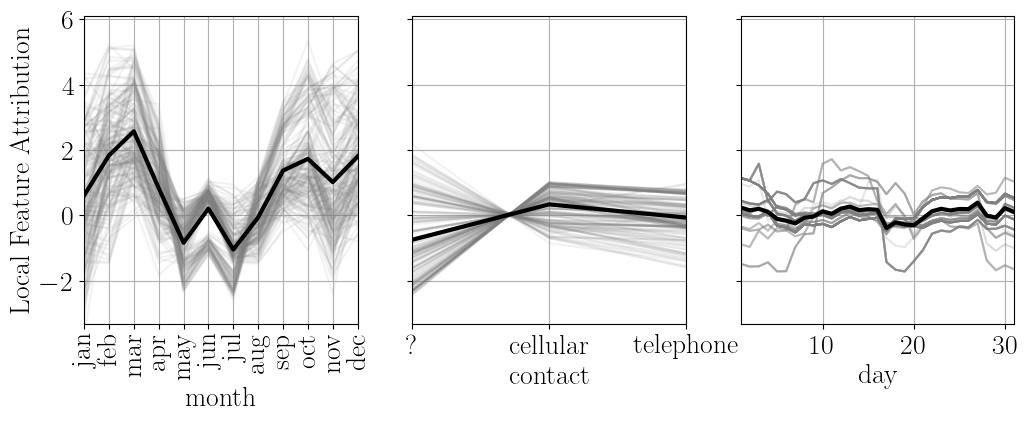

In [4]:
partial_dependence_plot(
    decomposition, background, features, idxs=[5, 6, 14], figsize=(12, 4), centered=True
)
plt.savefig(os.path.join("results", "LFA_ebm_marketing.pdf"), bbox_inches="tight")


In [5]:
start = time.time()
partition = TabularAGREED(
    model.decision_function,
    background,
    threshold=0.25,
    max_group_size=3,
    verbose=True,
)
display(f"AGREED took {time.time() - start: .2f} seconds")
features_to_group = [group for group in partition.Imap_inv if len(group) > 1]
grouped_features = features.group(features_to_group)
grouped_features.summary()



Running AGREED with settings:
    features_to_ignore: None
    min_potential: 0.0
    max_group_size: 3
Init Disagreement :  5.70e+00
Disagreement :  2.56e+00
Disagreement :  1.23e+00
Exited because disagreements fell bellow threshold



'AGREED took  26.04 seconds'

|Idx|        Name        |        Type        |    Card    |      Groups      |
-------------------------------------------------------------------------------
| 0 | age                | num_int            | 78         | [0]              |
| 1 | default            | bool               | 2          | [1]              |
| 2 | balance            | num                | inf        | [2]              |
| 3 | housing            | bool               | 2          | [3]              |
| 4 | loan               | bool               | 2          | [4]              |
| 5 | duration           | num                | inf        | [7]              |
| 6 | campaign           | num                | inf        | [8]              |
| 7 | pdays              | num                | inf        | [9]              |
| 8 | previous           | num                | inf        | [10]             |
| 9 | job                | ordinal            | 12         | [11]             |
| 10| marital            | ordinal      

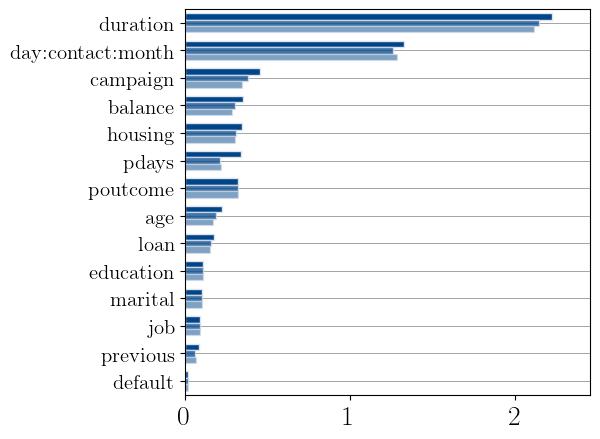

In [6]:
# Compute the functional decomposition while treating features as groups
grouped_decomposition = get_components_ebm(
    model,
    background,
    background,
    grouped_features,
    anchored=True,
)
grouped_shap_values = shap_from_decomposition(
    get_interventional_from_anchored(grouped_decomposition)
)
grouped_I_PDP, grouped_I_PFI = get_PDP_PFI_importance(grouped_decomposition)
grouped_I_SHAP = get_SHAP_importance(grouped_shap_values)

bar(
    [grouped_I_PFI, grouped_I_SHAP, grouped_I_PDP],
    feature_labels=grouped_features.names(),
)
plt.savefig(
    os.path.join("results", "grouped_GFI_ebm_marketing.pdf"), bbox_inches="tight"
)



In [7]:
def get_region(X):
    region = np.zeros(X.shape[0])
    region[(X[:, 14] == 0)] = 0
    region[(X[:, 14] == 1)] = 1
    region[(X[:, 14] == 2)] = 2
    return region


# Use more data as the background for the plot
large_background = x_train
grouped_decomposition = get_components_ebm(
    model,
    large_background,
    large_background,
    grouped_features,
    anchored=False,
)
labels = [r"Contact=?", r"Contact=cellular", r"Contact=telephone"]
regions = get_region(large_background)
joint_effect = grouped_decomposition[(13,)]


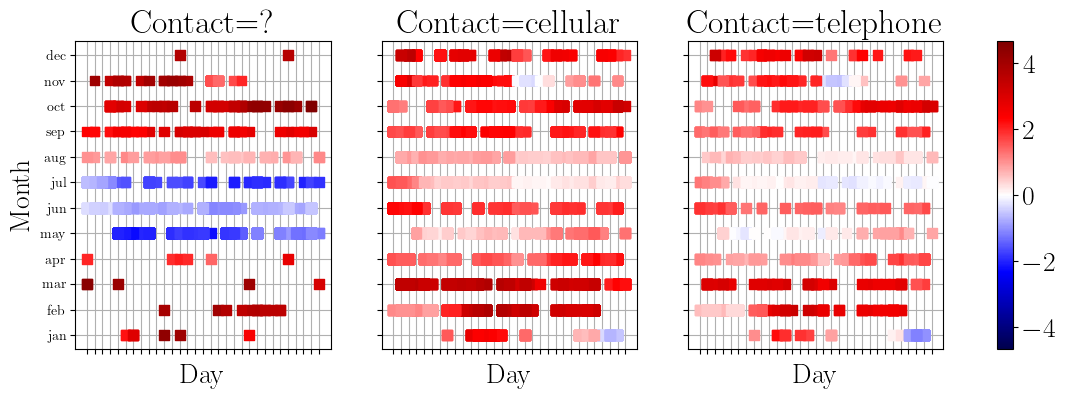

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import matplotlib.cm as cm

normalizer = CenteredNorm(0, np.abs(0 - joint_effect).max())

# Plot the joint effect of three variables at the same time
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for r in range(3):
    subset = np.where(regions == r)[0]
    background_subset = large_background[subset]
    joint_effect_subset = joint_effect[subset]
    # Plot at most n_curves ICE curves
    axes[r].scatter(
        background_subset[:, 5],
        background_subset[:, 6],
        c=joint_effect_subset,
        marker="s",
        s=50,
        cmap="seismic",
        norm=normalizer,
        zorder=2,
    )
    if r == 0:
        axes[r].set_ylabel("Month")
        axes[r].set_yticks(
            np.arange(12), labels=features.feature_objs[6].cats, fontsize=10
        )
    else:
        axes[r].set_yticks(np.arange(12))
        axes[r].set_yticklabels([])
    axes[r].set_title(labels[r])
    axes[r].set_xlabel("Day")
    axes[r].set_xticks(np.arange(1, 32))
    axes[r].set_xticklabels([])
    axes[r].grid("on", zorder=-1)
fig.colorbar(
    ax=axes.ravel().tolist(),
    mappable=cm.ScalarMappable(norm=normalizer, cmap="seismic"),
)
plt.savefig(
    os.path.join("results", "grouped_LFA_ebm_marketing.png"), bbox_inches="tight"
)


In [9]:
# [Bonus] We could further decompose the joint attribution of day-month-contact
# three main effects + three pairwise interactions + a three-way interaction
# joint effect = h_1 + h_2 + h_3 + h_12 + h_23 + h_13 + h_123
decomposition = get_components_ebm(
    model, large_background, large_background, features, anchored=False
)
# Since this model only involves two-way interactions, we need visualize at
# most 6 functions. To improve interpretability, we can post-process the components
# by centering them.
centered_decomposition = {}
centered_decomposition[()] = decomposition[()]
for key, component in decomposition.items():
    if len(key) > 0:
        centered_decomposition[key] = component
        mean_component = component.mean()
        centered_decomposition[key] = decomposition[key] - mean_component
        centered_decomposition[()] = decomposition[()] + mean_component
display(centered_decomposition.keys())


dict_keys([(), (0,), (1,), (2,), (3,), (4,), (5,), (6,), (3, 6), (5, 6), (7,), (0, 7), (2, 7), (3, 7), (4, 7), (6, 7), (8,), (6, 8), (7, 8), (9,), (6, 9), (7, 9), (10,), (7, 10), (11,), (12,), (13,), (14,), (6, 14), (7, 14), (15,), (7, 15)])

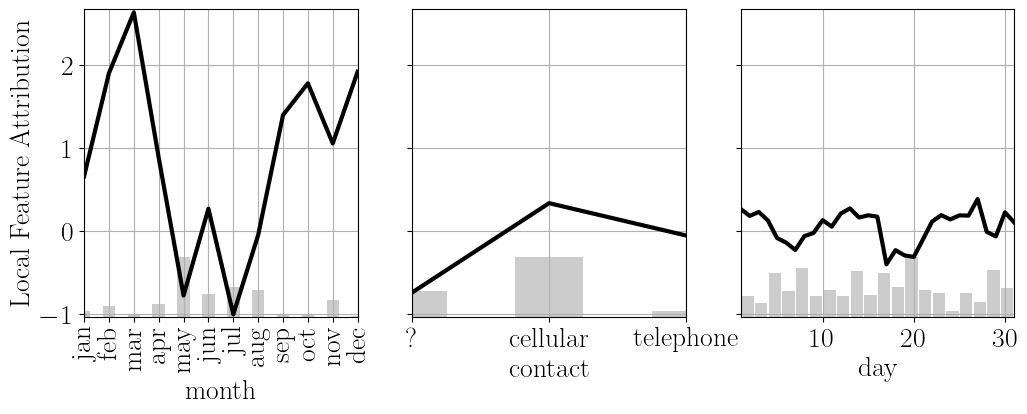

In [10]:
partial_dependence_plot(
    centered_decomposition, large_background, features, idxs=[5, 6, 14], figsize=(12, 4)
)


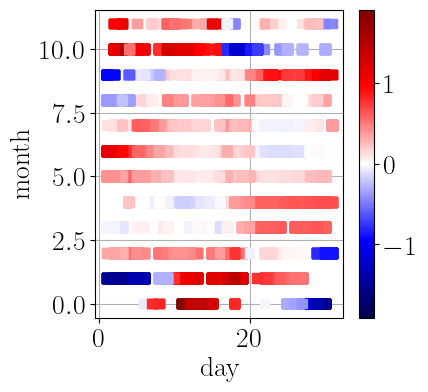

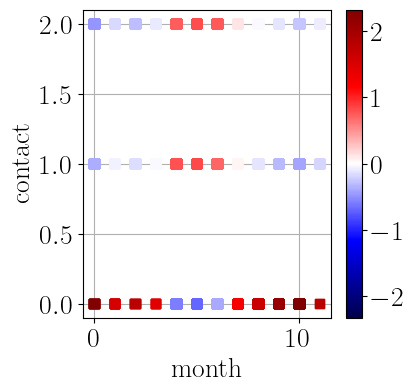

In [11]:
from itertools import combinations

# Plot the joint effect of three variables at the same time
for i, j in combinations([5, 6, 14], 2):
    # Plot at most n_curves ICE curves
    if (i, j) in centered_decomposition.keys():
        normalizer = CenteredNorm(0, np.abs(centered_decomposition[(i, j)].max()))
        fig, axes = plt.subplots(1, 1, figsize=(4, 4))
        axes.scatter(
            large_background[:, i],
            large_background[:, j],
            c=centered_decomposition[(i, j)],
            marker="s",
            s=50,
            cmap="seismic",
            norm=normalizer,
            zorder=2,
        )
        axes.set_xlabel(features.names()[i])
        axes.set_ylabel(features.names()[j])
        axes.grid("on", zorder=-1)
        fig.colorbar(
            ax=axes, mappable=cm.ScalarMappable(norm=normalizer, cmap="seismic")
        )